<a href="https://colab.research.google.com/github/xErnyx/Practica_3_El_Perceptron/blob/main/Practica_3_El_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Practica N°3: El Perceptrón**
---
Juan D. Figueroa

Universidad Salesiana del Ecuador - Sede sur

Inteligencia Artificial

Ciencias de la computación

Ing. Rodrigo Tufiño

13 de noviembre del 2026

# **📌 Introducción**
---
El perceptrón es la unidad más simple del aprendizaje supervisado: no es una "red neuronal", sino una unidad de decisión lineal que combina sus entradas con pesos y separa dos clases con una recta (Rosenblatt, 1958). Su idea parte del modelo de neurona artificial de McCulloch y Pitts (1943).

El trabajo se organiza en nueve fases. La Fase 1 explora el dataset de 23 puntos bidimensionales. La Fase 2 implementa el modelo (pesos, activación y salida). La Fase 3 visualiza la frontera de decisión. La Fase 4 implementa la regla de aprendizaje. La Fase 5 entrena con lr = 0.5. La Fase 6 clasifica instancias nuevas. Las Fases 7 y 8 analizan la evolución de la frontera y del error. La Fase 9 compara tres tasas de aprendizaje. Todo se programa a mano con NumPy (Harris et al., 2020) y matplotlib (Hunter, 2007), sin librerías de machine learning. Cada fase presenta el fundamento teórico, el código paso a paso y las respuestas a las preguntas de la guía (Tufiño, 2026).

# **🎯 Objetivos**
---
**Objetivo general**

Implementar y analizar un perceptrón desde cero para clasificar datos bidimensionales en dos clases, interpretando cómo sus pesos definen la frontera de decisión.

**Objetivos específicos**

1.   Implementar manualmente la función de activación, la propagación hacia adelante y la regla de actualización de pesos.
2.   Entrenar un perceptrón sin utilizar librerías de machine learning.
3.   Visualizar la frontera de decisión y su evolución durante el entrenamiento.
4.   Analizar la influencia de la tasa de aprendizaje en la convergencia del modelo.
5.   Evaluar el comportamiento del modelo con instancias no utilizadas en el entrenamiento.

# **🛠️ Verificación del entorno**
---
En Colab, NumPy y matplotlib ya vienen instalados, por lo que solo se importan. Se fija una **semilla** (`np.random.seed`) al inicio para que los pesos aleatorios, y por tanto todos los resultados de este notebook, sean reproducibles (buena práctica del taller de NumPy).

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)   # reproducibilidad: mismos pesos aleatorios en cada ejecución
print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


# **📐 Fase 1 Exploración del Dataset**
---
**Fundamento teórico**

1.   El perceptrón trabaja con datos **numéricos**. Cada **instancia** (fila) tiene dos variables de entrada, x₁ y x₂ (las *features*), y una etiqueta de salida y ∈ {−1, +1} (el *label*).
2.   En NumPy, el conjunto de entradas se guarda como una **matriz** `X` de forma (n_instancias, n_features) y las etiquetas como un **vector** `y` de forma (n_instancias,).
3.   Un problema es de **clasificación binaria** cuando la salida solo puede tomar dos valores posibles (dos clases).

# 1. Actividad 1.1: Carga del dataset
---
Se crean `X` e `y` con los 23 puntos de la tabla de la guía: las primeras 14 filas son la clase −1 y las últimas 9 la clase +1.

In [4]:
# Matriz X: cada fila es [x1, x2]
X = np.array([
    [1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2], [6, 0], [7, 4],
    [9, 3], [9, 1], [11, 1], [12, 3], [16, 2],          # clase -1  (14 puntos)
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11], [12, 9],
    [12, 6], [14, 7], [16, 4]                           # clase +1  (9 puntos)
])

# Vector y: una etiqueta por fila de X
y = np.array([-1]*14 + [1]*9)

print("X:\n", X)
print("\ny:", y)

X:
 [[ 1  7]
 [ 1  3]
 [ 3  4]
 [ 4  6]
 [ 4  2]
 [ 6  6]
 [ 6  2]
 [ 6  0]
 [ 7  4]
 [ 9  3]
 [ 9  1]
 [11  1]
 [12  3]
 [16  2]
 [ 4  8]
 [ 6  8]
 [ 8  9]
 [ 9  7]
 [10 11]
 [12  9]
 [12  6]
 [14  7]
 [16  4]]

y: [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1  1  1  1  1  1  1  1  1]


# 2. Actividad 1.a: Inspección inicial
---
La guía pide contar instancias, variables de entrada, clases y puntos por clase **sin librerías de análisis de datos**, solo con ciclos, contadores y listas. Por eso no se usa `.shape` ni `np.unique` para el conteo; se verifican después como comprobación.

In [5]:
# ── Conteo con ciclos y contadores ────────────────────────────────
total = 0
for fila in X:
    total += 1                       # una vuelta por instancia

variables_entrada = 0
for valor in X[0]:
    variables_entrada += 1           # cuántos valores tiene una fila

clases = []                          # lista de clases distintas
conteo = {}                          # contador por clase
for etiqueta in y:
    etiqueta = int(etiqueta)          # entero de Python (salida más limpia)
    if etiqueta not in clases:
        clases.append(etiqueta)
        conteo[etiqueta] = 0
    conteo[etiqueta] += 1

print("Instancias totales    :", total)
print("Variables de entrada  :", variables_entrada)
print("Número de clases      :", len(clases), "→", sorted(clases))
for c in sorted(conteo):
    print(f"Puntos en la clase {c:>2}  :", conteo[c])

# ── Verificación rápida con NumPy (Módulo 2 del taller) ───────────
print("\nVerificación → X.shape:", X.shape, "| y.shape:", y.shape)

Instancias totales    : 23
Variables de entrada  : 2
Número de clases      : 2 → [-1, 1]
Puntos en la clase -1  : 14
Puntos en la clase  1  : 9

Verificación → X.shape: (23, 2) | y.shape: (23,)


*P1. ¿Qué representa cada fila de X? ¿Qué representa cada valor del vector y? ¿Por qué este problema se considera de clasificación binaria?*

**Respuesta:** Cada fila de `X` es **una instancia**, es decir, un punto del plano descrito por sus dos coordenadas [x₁, x₂]. `X` tiene 23 filas y 2 columnas. Cada valor de `y` es **la clase real** (el label) de la fila correspondiente: −1 o +1; el valor `y[i]` pertenece al punto `X[i]`. Es un problema de **clasificación binaria** porque la salida solo puede tomar dos valores (−1 y +1): el modelo debe decidir a cuál de las dos clases pertenece cada punto. Hay 14 puntos de la clase −1 y 9 de la clase +1, por lo que las clases están algo desbalanceadas.

# 3. Actividad 1.b: Separación visual de las clases
---
Se crea una función que grafica cada clase con un marcador distinto (círculo azul para −1 y cruz roja para +1, como en la figura de la guía). Se usan máscaras booleanas (Módulo 3 del taller): `X[y == -1]` devuelve solo las filas de esa clase.

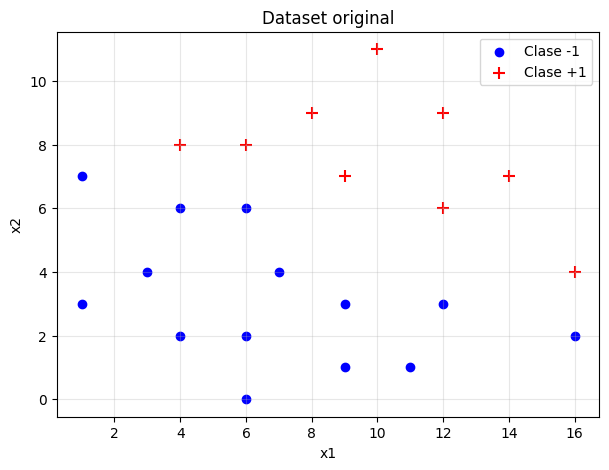

In [6]:
def plot_dataset(X, y, title="Dataset"):
    '''Grafica los puntos de ambas clases con marcadores distintos.'''
    plt.figure(figsize=(7, 5))
    plt.scatter(X[y == -1, 0], X[y == -1, 1], c="blue", marker="o", label="Clase -1")
    plt.scatter(X[y == 1, 0],  X[y == 1, 1],  c="red",  marker="+", s=80, label="Clase +1")
    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_dataset(X, y, "Dataset original")

*P2. Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta.*

**Respuesta:** **Sí parece posible, pero con poco margen.** La clase +1 (cruces rojas) ocupa la parte superior y la derecha del plano, y la clase −1 (círculos azules) la parte inferior y la izquierda. Se puede imaginar una recta con pendiente negativa que baje desde la zona de (1, 8) hacia (16, 3.5) y deje cada clase de un lado. Sin embargo, algunos puntos de ambas clases quedan muy próximos entre sí, por ejemplo (6, 6) de la clase −1 frente a (6, 8) de la clase +1, o (16, 2) frente a (16, 4). Esto anticipa que el perceptrón sí podrá converger (los datos son **linealmente separables**), pero que la recta correcta es estrecha y tomará varias épocas encontrarla.

**Entregable de la Fase 1:** conteo de instancias totales (23), conteo por clase (14 y 9), gráfica inicial de los puntos y respuestas a las preguntas guía (P1 y P2).

# **📐 Fase 2 Fundamento del Perceptrón**
---
**Fundamento teórico**

1.   El perceptrón es un clasificador lineal supervisado: recibe entradas numéricas, calcula una **suma ponderada**, aplica una **función de activación** y produce una salida binaria.
2.   Para una instancia x = [x₁, x₂] calcula: `z = w₀ + w₁·x₁ + w₂·x₂`, donde w₀ es el **bias** (sesgo), w₁ el peso de x₁ y w₂ el peso de x₂.
3.   La salida usa la **función escalón bipolar**: ŷ = +1 si z ≥ 0, y ŷ = −1 si z < 0.
4.   La **frontera de decisión** es el conjunto de puntos donde z = 0, es decir `w₀ + w₁·x₁ + w₂·x₂ = 0`. En 2 dimensiones es una recta.

# 1. Actividad 2.a: Vector de pesos
---
`initialize_weights()` devuelve tres pesos aleatorios pequeños en el intervalo [−0.5, 0.5]. Se usa `np.random.uniform(low, high, size)`, que genera valores uniformes en ese rango (a diferencia de `rand`, que solo genera en [0, 1)).

In [7]:
def initialize_weights():
    '''Devuelve [w0, w1, w2]: tres pesos aleatorios en [-0.5, 0.5].'''
    return np.random.uniform(-0.5, 0.5, 3)

w_prueba = initialize_weights()
print("Pesos de prueba:", w_prueba.round(4))
print("shape:", w_prueba.shape, "| dentro de [-0.5, 0.5]:", bool(np.all(np.abs(w_prueba) <= 0.5)))

Pesos de prueba: [-0.1255  0.4507  0.232 ]
shape: (3,) | dentro de [-0.5, 0.5]: True


*P3. ¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene dos variables? ¿Qué función cumple el bias en el modelo?*

**Respuesta:** Porque además de un peso por cada variable de entrada (w₁ para x₁ y w₂ para x₂) el modelo tiene un tercer parámetro, el **bias** w₀, que no se multiplica por ninguna entrada. El bias **desplaza la frontera** de decisión: sin él, la recta w₁x₁ + w₂x₂ = 0 estaría obligada a pasar por el origen (0, 0) y solo podría rotar, lo que impediría separar conjuntos que no están centrados en el origen, como este dataset. Con el bias, la recta puede rotar (por w₁ y w₂) y también trasladarse (por w₀).

# 2. Actividad 2.b: Función de activación
---
Implementa el escalón bipolar. Se incluye `z = 0` en la clase +1, tal como indica la fórmula (z ≥ 0).

In [8]:
def activation(z):
    '''Escalón bipolar: +1 si z >= 0, -1 si z < 0.'''
    return 1 if z >= 0 else -1

# Prueba con valores negativos, cero y positivos
for z in [-2.5, -0.001, 0, 0.001, 3.7]:
    print(f"activation({z:>6}) = {activation(z):>2}")

activation(  -2.5) = -1
activation(-0.001) = -1
activation(     0) =  1
activation( 0.001) =  1
activation(   3.7) =  1


*P4. ¿Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1? ¿Qué ventaja tiene esta representación para el algoritmo del perceptrón?*

**Respuesta:** Con etiquetas −1 y +1 la **etiqueta coincide con el signo de z**: un punto está bien clasificado exactamente cuando y y z tienen el mismo signo. Además, la corrección `η(y − ŷ)x` vale 0 si acierta y ±2η·x si falla, lo que se interpreta geométricamente: cuando falla un punto de la clase +1 se **suma** el punto al vector de pesos (la frontera gira hacia él) y cuando falla uno de la clase −1 se **resta**. Con etiquetas 0 y 1 el algoritmo también funcionaría (la diferencia valdría 0, +1 o −1 y solo cambia la escala del paso), pero la representación bipolar es más simétrica: las dos clases quedan centradas en torno al cero de la función de activación y una sola expresión sirve para ambas.

# 3. Actividad 2.c: Cálculo de salida
---
`perceptron_compute(x, w)` recibe **una sola instancia** x = [x₁, x₂] y los pesos w = [w₀, w₁, w₂]; calcula la suma ponderada z y devuelve la salida de la activación.

In [9]:
def perceptron_compute(x, w):
    '''Salida del perceptrón para UNA instancia x = [x1, x2].'''
    z = w[0] + w[1] * x[0] + w[2] * x[1]     # suma ponderada
    return activation(z)                      # función escalón bipolar

# ── Prueba manual con tres instancias del dataset ─────────────────
w_demo = np.array([-8.0, 0.5, 1.0])           # pesos elegidos a mano para la prueba
for i in [0, 14, 22]:                         # instancias 0 (clase -1), 14 y 22 (clase +1)
    x = X[i]
    z = w_demo[0] + w_demo[1]*x[0] + w_demo[2]*x[1]
    print(f"x = {x}  z = {z:>5.1f}  salida = {perceptron_compute(x, w_demo):>2}  etiqueta real = {y[i]:>2}")

x = [1 7]  z =  -0.5  salida = -1  etiqueta real = -1
x = [4 8]  z =   2.0  salida =  1  etiqueta real =  1
x = [16  4]  z =   4.0  salida =  1  etiqueta real =  1


*P5. ¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón? ¿Por qué no basta con calcular solo z?*

**Respuesta:** La suma ponderada **z** es un número real cualquiera (en la prueba anterior valió −0.5 o 2.0 por ejemplo): mide *qué tan a un lado u otro* de la frontera está el punto. La **salida** del perceptrón es la decisión final de clase, +1 o −1, que resulta de aplicar el escalón a z. No basta con z porque el problema exige una **etiqueta de clase** y no un valor continuo; además, la regla de aprendizaje compara la etiqueta predicha ŷ con la real y, y para eso ambas deben ser −1 o +1.

**Entregable de la Fase 2:** funciones `initialize_weights()`, `activation(z)` y `perceptron_compute(x, w)` implementadas, prueba manual con tres instancias del dataset y respuestas a las preguntas guía (P3 a P5).

# **📐 Fase 3 Visualización de la Frontera de Decisión**
---
**Fundamento teórico**

1.   La frontera del perceptrón es la recta `w₀ + w₁x₁ + w₂x₂ = 0`. Si w₂ ≠ 0 se despeja x₂: `x₂ = −(w₀ + w₁x₁) / w₂`, y se puede graficar evaluando x₁ en dos extremos.
2.   **Caso especial:** si w₂ = 0 no se puede despejar x₂ (habría **división entre cero**). Entonces la recta es **vertical**: `x₁ = −w₀ / w₁` (si además w₁ = 0, no existe recta).
3.   Un lado de la recta es la región z > 0 (clase +1) y el otro la región z < 0 (clase −1). El vector (w₁, w₂) es **perpendicular** a la recta.

# 1. Actividad 3.a: Función de graficación
---
`perceptron_plot(X, y, w, title)` dibuja ambas clases y la frontera. Se fijan los límites de los ejes según los datos para que una recta muy inclinada no distorsione la gráfica. Se agrega un parámetro opcional `ax` (por defecto `None`) para poder reutilizar la función en varias subgráficas en las Fases 7 y 9 sin cambiar su uso con los 4 argumentos de la guía.

In [10]:
def perceptron_plot(X, y, w, title, ax=None):
    '''Grafica las dos clases y la frontera de decisión definida por w.'''
    propia = ax is None                           # ¿la función crea su propia figura?
    if propia:
        plt.figure(figsize=(7, 5))
        ax = plt.gca()

    ax.scatter(X[y == -1, 0], X[y == -1, 1], c="blue", marker="o", label="Clase -1")
    ax.scatter(X[y == 1, 0],  X[y == 1, 1],  c="red",  marker="+", s=80, label="Clase +1")

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    w0, w1, w2 = w

    if w2 != 0:                                   # caso normal: se despeja x2
        x1 = np.array([x1_min, x1_max])
        x2 = -(w0 + w1 * x1) / w2
        ax.plot(x1, x2, "k-", label="Frontera")
    elif w1 != 0:                                 # w2 = 0: recta vertical x1 = -w0/w1
        ax.axvline(-w0 / w1, color="k", label="Frontera (vertical)")
    # si w1 = w2 = 0 no existe recta que graficar

    ax.set_xlim(x1_min, x1_max)                   # los ejes no cambian aunque la recta sea muy inclinada
    ax.set_ylim(x2_min, x2_max)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.3)
    if propia:
        plt.show()

*P6. ¿Qué representa geométricamente la recta generada por el perceptrón? ¿Qué ocurre si los pesos iniciales son aleatorios?*

**Respuesta:** La recta es el **conjunto de puntos donde z = 0**: la **frontera de decisión** que divide el plano en dos semiplanos, uno donde el perceptrón responde +1 (z > 0) y otro donde responde −1 (z < 0). Su inclinación la determinan w₁ y w₂ (el vector (w₁, w₂) es perpendicular a la recta) y su posición la fija el bias w₀. Si los pesos iniciales son aleatorios, la recta inicial queda en una posición e inclinación **arbitrarias**, sin relación con los datos; por eso el entrenamiento debe corregirla.

# 2. Actividad 3.b: Gráfica con pesos iniciales
---

Pesos iniciales [w0, w1, w2]: [ 0.0987 -0.344  -0.344 ]


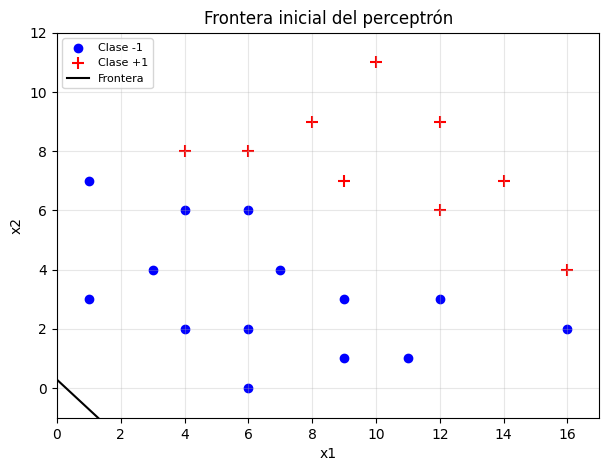

Errores de clasificación: 9 de 23


In [11]:
w_initial = initialize_weights()
print("Pesos iniciales [w0, w1, w2]:", w_initial.round(4))
perceptron_plot(X, y, w_initial, "Frontera inicial del perceptrón")

# ── ¿Cuántos puntos clasifica mal esta frontera? ──────────────────
errores = sum(perceptron_compute(xi, w_initial) != yi for xi, yi in zip(X, y))
print(f"Errores de clasificación: {errores} de {len(X)}")

*P7. ¿La frontera inicial clasifica correctamente los puntos? ¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?*

**Respuesta:** **No.** Con los pesos iniciales [0.099, -0.344, -0.344] la frontera clasifica mal **9 de los 23 puntos**: como w₁ y w₂ son negativos y las entradas son positivas, z resulta negativo para todos los puntos y el modelo predice -1 para **todas** las instancias (acierta solo los 14 de esa clase). No debería esperarse que fuera correcta porque los pesos se eligieron al azar, sin mirar los datos: la probabilidad de que una recta aleatoria separe dos clases es muy baja. Los pesos iniciales son solo un **punto de partida** que el algoritmo de aprendizaje debe mejorar.

**Entregable de la Fase 3:** función `perceptron_plot(X, y, w, title)`, gráfica con la frontera inicial, explicación de la frontera (fundamento teórico y P6) y respuestas a las preguntas guía (P6 y P7).

# **📐 Fase 4 Entrenamiento del Perceptrón**
---
**Fundamento teórico**

1.   El perceptrón aprende **modificando sus pesos solo cuando comete un error**. Para cada instancia se calcula la predicción ŷ; si ŷ ≠ y, se actualizan los pesos.
2.   Regla de actualización: `wᵢ ← wᵢ + η·(y − ŷ)·xᵢ` para los pesos de las entradas y `w₀ ← w₀ + η·(y − ŷ)` para el bias (equivale a una entrada x₀ = 1).
3.   η (`lr`) es la **tasa de aprendizaje**: controla el tamaño de cada corrección.
4.   Una **época** es una pasada completa por todo el dataset. Se entrena hasta que una época no tenga errores o se llegue a `max_epochs`.
5.   La **tasa de error** de una época es `E = errores / total de instancias`. Si hay una actualización por cada error, el número de actualizaciones de la época es igual al número de errores.
6.   Si el dataset es linealmente separable, el **teorema de convergencia del perceptrón** garantiza que el algoritmo termina en un número finito de actualizaciones (Rosenblatt, 1958).

# 1. Actividad 4.a, 4.b y 4.c: Función de aprendizaje
---
Se implementan juntas porque se calculan dentro del mismo ciclo: el error por época (4.b) y la copia de los pesos (4.c). Detalles de diseño:

*   `w` se copia al inicio (`w.copy()`) para **no modificar el vector que recibe**; así los pesos iniciales siguen disponibles después del entrenamiento.
*   `W_values` guarda en cada época una **copia** de los pesos (4.c). Se incluye además el estado inicial en la posición 0, que se necesita en la Fase 7 (por eso `len(W_values) = épocas + 1`).
*   `E_values` guarda un valor por época (la tasa de error de esa época).

In [12]:
def perceptron_learning(X, y, w, lr, max_epochs):
    '''Entrena el perceptrón. Devuelve:
       pesos finales, épocas, actualizaciones, W_values, E_values.'''
    w = np.array(w, dtype=float).copy()      # copia: no se modifica el vector original
    W_values = [w.copy()]                    # estado inicial (índice 0)
    E_values = []
    updates = 0
    epochs = 0

    for _ in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):             # una pasada completa = una época
            y_hat = perceptron_compute(xi, w)
            if y_hat != yi:                  # solo se actualiza si hay error
                w[0]   += lr * (yi - y_hat)          # bias
                w[1:]  += lr * (yi - y_hat) * xi     # w1, w2
                errors += 1
        updates += errors
        epochs  += 1
        E_values.append(errors / len(X))     # 4.b: tasa de error de la época
        W_values.append(w.copy())            # 4.c: COPIA de los pesos
        if errors == 0:                      # época sin errores → convergió
            break

    return w, epochs, updates, W_values, E_values

print("✅ perceptron_learning definida")

✅ perceptron_learning definida


Demostración de por qué se guarda una **copia** y no el propio vector (necesario para la pregunta P10):

In [13]:
# ── Sin copia: la lista guarda la MISMA referencia (como una vista en NumPy) ──
w_demo = np.array([0.0, 0.0, 0.0])
sin_copia, con_copia = [], []
for paso in range(3):
    w_demo += 1                    # se modifica el array en el sitio
    sin_copia.append(w_demo)       # guarda la referencia
    con_copia.append(w_demo.copy())  # guarda una copia independiente

print("Sin copia:", [v.tolist() for v in sin_copia])    # los tres iguales: todos apuntan al mismo array
print("Con copia:", [v.tolist() for v in con_copia])    # historia correcta
print("¿Misma referencia en memoria?", sin_copia[0] is sin_copia[2])

Sin copia: [[3.0, 3.0, 3.0], [3.0, 3.0, 3.0], [3.0, 3.0, 3.0]]
Con copia: [[1.0, 1.0, 1.0], [2.0, 2.0, 2.0], [3.0, 3.0, 3.0]]
¿Misma referencia en memoria? True


*P8. ¿Por qué es necesario incluir un número máximo de épocas? ¿Qué podría ocurrir si el dataset no fuera linealmente separable?*

**Respuesta:** Porque el criterio de parada "una época sin errores" **solo se alcanza si existe una recta que separe todos los puntos**. Si el dataset no fuera linealmente separable (por ejemplo, la función XOR), siempre quedaría algún punto mal clasificado, las actualizaciones nunca terminarían y el ciclo se repetiría **infinitamente**, con pesos que oscilan sin estabilizarse. El máximo de épocas es una **protección** que garantiza que el programa termine aunque no haya convergencia.

*P9. ¿Qué significa que la tasa de error llegue a cero?*

**Respuesta:** Significa que en esa época el perceptrón **clasificó correctamente las 23 instancias de entrenamiento** sin necesitar ninguna actualización de pesos; por lo tanto los pesos ya no cambian y el algoritmo **convergió**. Es un resultado sobre los datos de entrenamiento: no garantiza que el modelo acierte con datos nuevos (se analiza en P18).

*P10. ¿Por qué es importante guardar copias de los pesos y no solo el vector w? ¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?*

**Respuesta:** Porque `w` es un array de NumPy que se **modifica en el sitio** (`w[0] += ...`): si se guardara solo `w` en la lista, todos los elementos serían **referencias al mismo objeto** y al final contendrían el mismo valor, los pesos finales (como muestra la demostración: tres listas idénticas en `sin_copia`). Al graficar la evolución, las seis fronteras serían **la misma recta** y se perdería el historial del aprendizaje. Con `w.copy()` cada época conserva sus propios valores.

**Entregable de la Fase 4:** función `perceptron_learning(X, y, w, lr, max_epochs)` implementada, registro de errores por época (`E_values`), registro de pesos por época (`W_values`) y respuestas a las preguntas guía (P8 a P10).

# **📐 Fase 5 Entrenamiento con tasa de aprendizaje 0.5**
---
**Fundamento teórico**

Con lr = 0.5 y como máximo 1000 épocas se entrena desde nuevos pesos aleatorios. Como el dataset es linealmente separable, se espera que el error llegue a 0 antes de las 1000 épocas. Se compara también con una **verificación independiente**: evaluar los pesos finales sobre todo el dataset, fuera del ciclo de entrenamiento.

# 1. Actividad 5.a: Entrena el modelo
---

In [14]:
w = initialize_weights()

final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X,
    y,
    w,
    lr=0.5,
    max_epochs=1000
)

print("Pesos iniciales          :", w.round(4))          # w NO cambió gracias a la copia
print("Pesos finales            :", final_w.round(4))
print("Número de épocas         :", epochs)
print("Total de actualizaciones :", updates)
print("Error final              :", E_values[-1])

# ── Verificación independiente con los pesos finales ──────────────
errores = sum(perceptron_compute(xi, final_w) != yi for xi, yi in zip(X, y))
print(f"\nVerificación: {errores} errores sobre {len(X)} instancias")

Pesos iniciales          : [-0.4419  0.3662  0.1011]
Pesos finales            : [-71.4419   2.3662   9.1011]
Número de épocas         : 134
Total de actualizaciones : 413
Error final              : 0.0

Verificación: 0 errores sobre 23 instancias


*P11. ¿El perceptrón logró converger? ¿Cómo puedes comprobarlo usando la lista E_values y la gráfica final?*

**Respuesta:** **Sí convergió.** Entrenó **134 épocas** con **413 actualizaciones** y llegó a un error final de **0.0**, muy por debajo del límite de 1000 épocas. Se comprueba de tres formas: (1) el **último valor de `E_values` es 0.0** y es el primer cero de la lista (los 133 anteriores son mayores que 0); (2) la verificación independiente con los pesos finales da **0 errores** en las 23 instancias; (3) la gráfica final (siguiente actividad) muestra una recta con cada clase completa en su lado.

# 2. Actividad 5.b: Frontera final
---

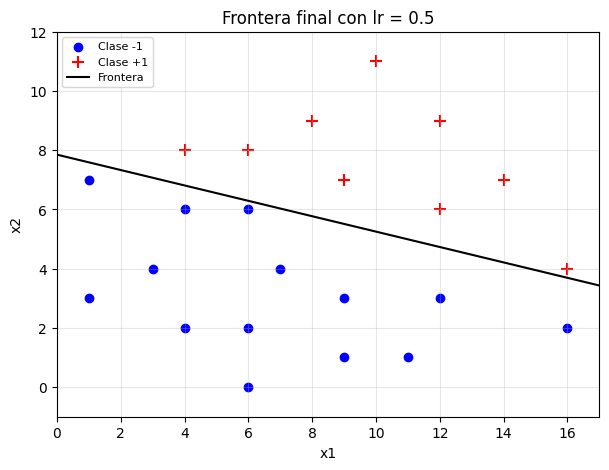

In [15]:
perceptron_plot(X, y, final_w, "Frontera final con lr = 0.5")

*P12. ¿La frontera final separa correctamente las dos clases? ¿Qué diferencias observas respecto a la frontera inicial?*

**Respuesta:** **Sí**, los círculos azules quedan en un lado y las cruces rojas en el otro, sin ningún punto mal clasificado. Respecto a la frontera inicial, que dejaba todo el dataset de un solo lado, la final está **muy desplazada y rotada**: pasó de pesos pequeños (|w| < 0.5) a w = [-71.442,   2.366,   9.101]. El bias cambió de forma muy marcada (a ≈ -71.4) porque la frontera tuvo que trasladarse hacia el interior del dataset, y la pendiente −w₁/w₂ ≈ -0.26 es negativa, tal como se intuía en P2. Los pesos son grandes porque cada error suma `lr·2·x` y los datos tienen valores de hasta 16.

**Entregable de la Fase 5:** entrenamiento completo con lr = 0.5, pesos iniciales y finales, número de épocas, número de actualizaciones, gráfica de la frontera final y respuestas a las preguntas guía (P11 y P12).

# **📐 Fase 6 Predicción con Nuevas Instancias**
---
**Fundamento teórico**

Un modelo entrenado se usa para clasificar **instancias que no vio durante el entrenamiento** (generalización). Se calcula z con los pesos finales: su signo indica en qué lado de la frontera cae el punto, y su magnitud indica qué tan lejos está (un |z| pequeño es un punto cercano a la frontera, es decir, una predicción poco segura).

# 1. Actividad 6.a: Clasificación de nuevas instancias
---
*Nota sobre la guía: la actividad indica `perceptron_compute(X_test, final_w)`, pero esa función (2.c) está definida para **una sola instancia**. Aquí se aplica a cada fila de `X_test` con una list comprehension (Módulo 1 del taller).*

In [16]:
X_test = np.array([
    [5, 5],
    [10, 6],
    [6, 10]
])

# perceptron_compute recibe UNA instancia → se aplica a cada fila
salidas = [perceptron_compute(x, final_w) for x in X_test]

# Tabla con el formato de la guía (se agrega z para ver qué tan lejos de la frontera cae cada punto)
print(f"{'Instancia':<12}{'Salida predicha':<18}{'z'}")
for x, s in zip(X_test, salidas):
    z = final_w[0] + final_w[1:] @ x
    print(f"{str(x.tolist()):<12}{s:<18}{z:.2f}")

Instancia   Salida predicha   z
[5, 5]      -1                -14.11
[10, 6]     1                 6.83
[6, 10]     1                 33.77


*P13. ¿Las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión?*

**Respuesta:** **Sí.** Las predicciones son [5, 5] → **-1**, [10, 6] → **1** y [6, 10] → **1**. Visualmente, [5, 5] queda debajo de la recta, en la zona de los círculos azules (clase −1); [10, 6] queda ligeramente por encima, entre cruces rojas (clase +1); y [6, 10] queda muy arriba, en la zona claramente roja. Los valores de z lo confirman: -14.1, 6.8 y 33.8. El signo coincide con el lado del plano y la magnitud con la distancia a la frontera.

# 2. Actividad 6.b: Dataset extendido
---
Se crea una **copia** del dataset (`.copy()`, para no modificar el original) y se le agregan las nuevas instancias con `np.vstack` y `np.concatenate` (Módulo 4 del taller), usando como etiquetas las salidas **predichas**.

X_ext: (26, 2) | y_ext: (26,)
Originales: 23 | Extendido: 26
¿X original intacto? → True


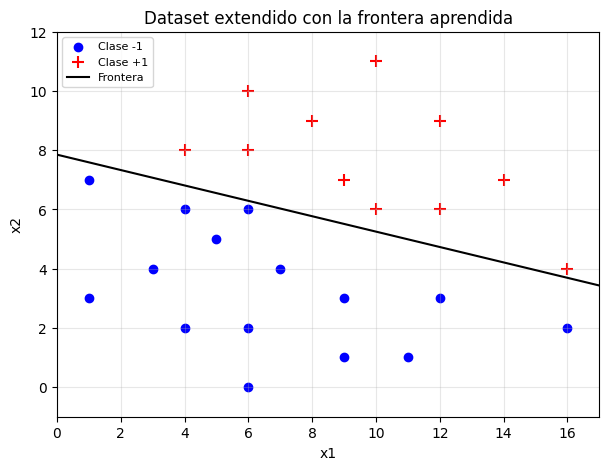

In [17]:
X_ext = np.vstack([X.copy(), X_test])                     # filas nuevas debajo
y_ext = np.concatenate([y.copy(), np.array(salidas)])     # etiquetas predichas al final

print("X_ext:", X_ext.shape, "| y_ext:", y_ext.shape)
print("Originales:", len(X), "| Extendido:", len(X_ext))
print("¿X original intacto? →", X.shape == (23, 2))

perceptron_plot(X_ext, y_ext, final_w, "Dataset extendido con la frontera aprendida")

*P14. ¿Las nuevas instancias quedaron ubicadas en la región esperada del plano? ¿Alguna predicción parece discutible? Justifica tu respuesta.*

**Respuesta:** Sí, las tres quedaron en el lado esperado según su posición. La predicción más **discutible es [10, 6]** (clase +1), porque su z = 6.8 es la más cercana a cero, es decir, está más cerca de la frontera; además queda entre puntos de ambas clases, como (9, 7) de la clase +1 y (9, 3) y (12, 3) de la clase −1. Al ser una frontera con poco margen, un pequeño cambio en los pesos podría moverla. [6, 10] es la más segura (z = 33.8). **Una aclaración importante:** en el dataset extendido estas tres instancias llevan la etiqueta *predicha*, no una etiqueta real, por lo que sus colores en la gráfica reflejan lo que predijo el modelo y no una verdad confirmada.

**Entregable de la Fase 6:** tabla con las predicciones de las tres nuevas instancias, dataset extendido, gráfica del dataset extendido y respuestas a las preguntas guía (P13 y P14).

# **📐 Fase 7 Evolución de la Frontera de Decisión**
---
**Fundamento teórico**

1.   Como los pesos definen la frontera, cada actualización de pesos **mueve o rota la recta**. Al guardar una copia de los pesos por época (`W_values`), se puede reconstruir la historia.
2.   Para elegir seis momentos (0 %, 20 %, 40 %, 60 %, 80 % y 100 % del entrenamiento) se usa `np.linspace(0, épocas, 6)`, redondeado a enteros, como índices de `W_values`. Esto es un caso de **fancy indexing** (Módulo 3 del taller).
3.   Si el entrenamiento tuvo menos de seis épocas se grafican todos los estados disponibles.

# 1. Actividad 7.a: Seis estados del entrenamiento
---
Se define una función reutilizable `plot_evolution` porque se necesitará de nuevo en la Fase 9.

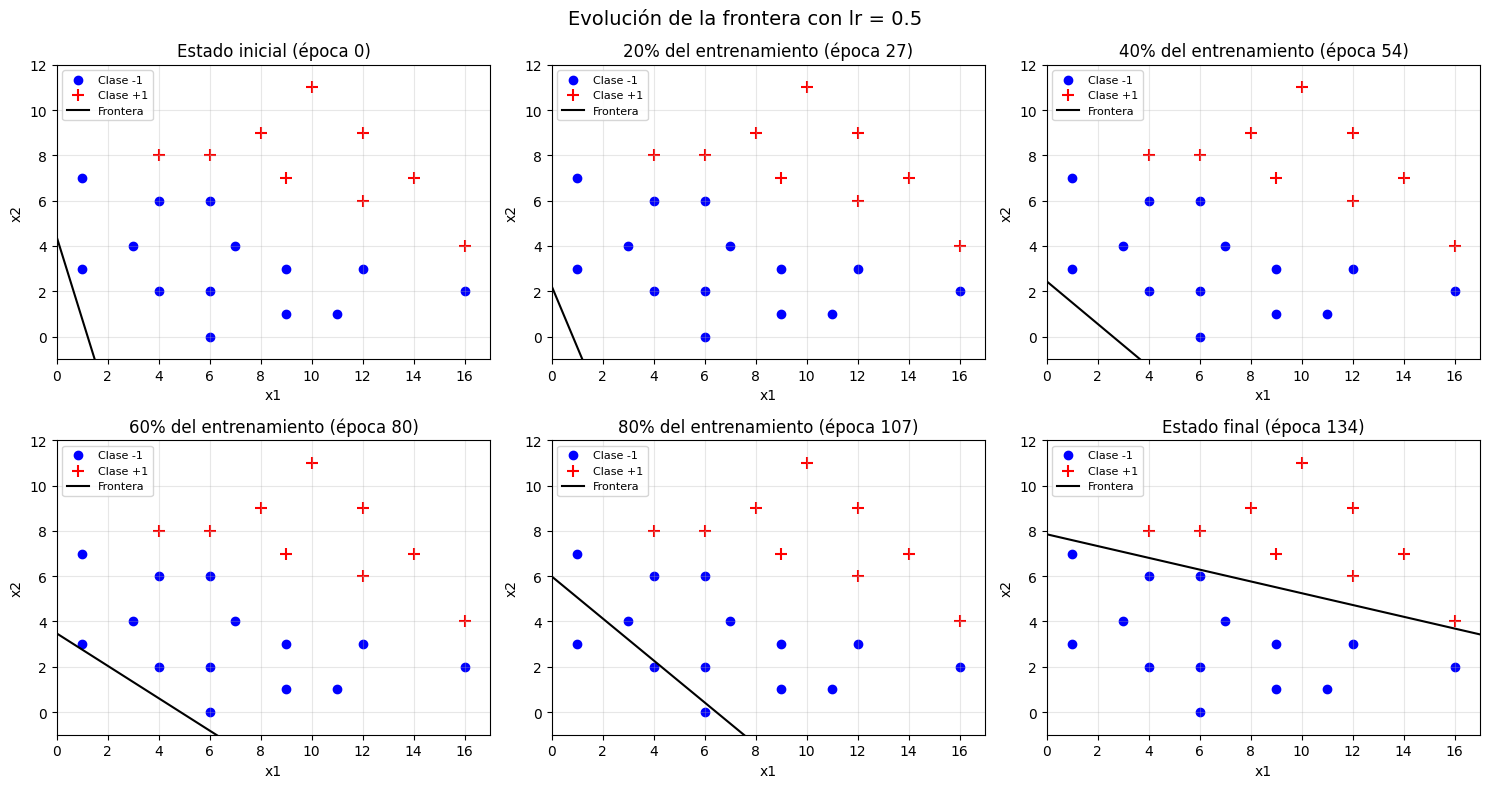

Épocas graficadas: [0, 27, 54, 80, 107, 134]
Época   0: pesos = [-0.44  0.37  0.1 ] → 14 errores de 23
Época  27: pesos = [-13.44  16.37   6.1 ] → 14 errores de 23
Época  54: pesos = [-29.44  11.37  12.1 ] → 14 errores de 23
Época  80: pesos = [-45.44   9.37  13.1 ] → 14 errores de 23
Época 107: pesos = [-60.44   9.37  10.1 ] → 11 errores de 23
Época 134: pesos = [-71.44   2.37   9.1 ] → 0 errores de 23


In [18]:
def plot_evolution(W_values, X, y, titulo):
    '''Grafica hasta 6 estados de la frontera: inicial, 20%, 40%, 60%, 80% y final.'''
    n_epocas = len(W_values) - 1                    # W_values incluye el estado inicial
    if n_epocas + 1 < 6:
        indices = list(range(n_epocas + 1))         # pocos estados: se grafican todos
    else:
        indices = np.round(np.linspace(0, n_epocas, 6)).astype(int)
    porcentajes = [round(100 * i / n_epocas) for i in indices]

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, i, p in zip(axes.ravel(), indices, porcentajes):
        etapa = "Estado inicial" if i == 0 else ("Estado final" if i == n_epocas else f"{p}% del entrenamiento")
        perceptron_plot(X, y, W_values[i], f"{etapa} (época {i})", ax=ax)
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()
    return indices

indices = plot_evolution(W_values, X, y, "Evolución de la frontera con lr = 0.5")
print("Épocas graficadas:", [int(i) for i in indices])

# ── Errores de cada estado, para describir lo que se ve ──────────
for i in indices:
    e = sum(perceptron_compute(xi, W_values[i]) != yi for xi, yi in zip(X, y))
    print(f"Época {int(i):>3}: pesos = {W_values[i].round(2)} → {e} errores de {len(X)}")

*P15. ¿Qué ocurre con la frontera de decisión a medida que se actualizan los pesos? ¿El cambio parece estable o brusco?*

**Respuesta:** La frontera **se va desplazando y girando** hasta separar las clases, pero el cambio es **brusco e irregular**, no una mejora suave. En las épocas [0, 27, 54, 80, 107, 134] los errores sobre el dataset completo fueron [14, 14, 14, 14, 11, 0]: la frontera siguió clasificando mal 14 puntos durante buena parte del recorrido aunque los pesos ya habían cambiado mucho (en la época 27, w₁ valía 16.4 frente a 0.37 al inicio), y solo hacia el final bajó a 11 y luego a 0. Cada actualización corrige el punto que falló, pero ese ajuste puede dejar mal clasificados otros puntos: el perceptrón no minimiza el error global de forma monótona. Además cada corrección suma `lr·2·x` y con valores de x de hasta 16 los saltos son grandes.

# 2. Actividad 7.b: Interpretación geométrica
---
Para responder se compara cómo cambian los pesos entre el estado inicial y el final, y la pendiente de la recta (−w₁/w₂) y su intercepto con x₂ (−w₀/w₂).

In [19]:
w_i, w_f = W_values[0], W_values[-1]
print("Pesos iniciales:", w_i.round(3), "→ pendiente = -w1/w2 =", round(-w_i[1]/w_i[2], 3))
print("Pesos finales  :", w_f.round(3), "→ pendiente = -w1/w2 =", round(-w_f[1]/w_f[2], 3))
print("Intercepto final con x2 (x1 = 0): -w0/w2 =", round(-w_f[0]/w_f[2], 3))
print("\nCambio absoluto de cada peso:", np.abs(w_f - w_i).round(2))

Pesos iniciales: [-0.442  0.366  0.101] → pendiente = -w1/w2 = -3.621
Pesos finales  : [-71.442   2.366   9.101] → pendiente = -w1/w2 = -0.26
Intercepto final con x2 (x1 = 0): -w0/w2 = 7.85

Cambio absoluto de cada peso: [71.  2.  9.]


*P16. ¿Qué peso parece influir más en la inclinación de la recta? ¿Qué papel parece cumplir el bias en el desplazamiento de la frontera?*

**Respuesta:** La **inclinación** depende de la **relación entre w₁ y w₂** (pendiente = −w₁/w₂); en este dataset w₂ (≈ 9.1) terminó mayor que w₁ (≈ 2.4), por lo que la recta quedó con pendiente suave y negativa (≈ -0.26). Un w₂ grande hace la recta más horizontal y un w₁ grande la haría más vertical. El **bias w₀** cumple el papel de **desplazar** la recta sin cambiar su inclinación: pasó de ≈ -0.44 a ≈ -71.4, y eso la movió hacia arriba hasta cortar el eje x₂ en ≈ 7.8. Ese desplazamiento fue el cambio **más grande** de todos los pesos, lo que indica que el bias es esencial en este problema.

**Entregable de la Fase 7:** seis gráficas de evolución de la frontera (Actividad 7.a), comentario escrito sobre la evolución observada (P15 y P16) y respuestas a las preguntas guía.

# **📐 Fase 8 Evolución del Error**
---
**Fundamento teórico**

1.   La gráfica de la tasa de error por época muestra **cuándo y cómo** converge el entrenamiento.
2.   El error del perceptrón **no tiene por qué descender de forma monótona**: se mide durante la pasada, mientras los pesos cambian con cada corrección.
3.   Un error de entrenamiento igual a cero solo dice que el modelo acierta **los datos con los que se entrenó**.

# 1. Actividad 8.a: Gráfica de error
---

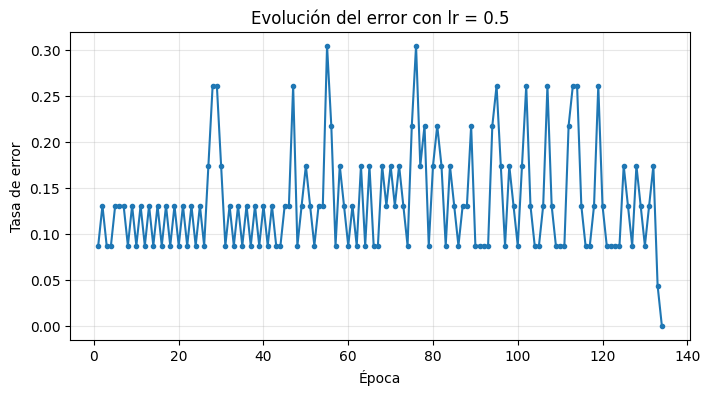

Error máximo: 0.304 (época 55 )
Veces que el error SUBIÓ respecto a la época anterior: 55
Épocas con el mismo error que la anterior: 20
Primera época con error 0: 134


In [20]:
def plot_error(E_values, title):
    '''Grafica la tasa de error (eje Y) contra la época (eje X).'''
    epocas = np.arange(1, len(E_values) + 1)     # épocas numeradas desde 1
    plt.figure(figsize=(8, 4))
    plt.plot(epocas, E_values, marker="o", markersize=3)
    plt.title(title)
    plt.xlabel("Época")
    plt.ylabel("Tasa de error")
    plt.grid(True, alpha=0.3)
    plt.show()

plot_error(E_values, "Evolución del error con lr = 0.5")

# ── Datos para describir la gráfica ───────────────────────────────
E = np.array(E_values)
print("Error máximo:", E.max().round(3), "(época", int(E.argmax()) + 1, ")")
print("Veces que el error SUBIÓ respecto a la época anterior:", int(np.sum(E[1:] > E[:-1])))
print("Épocas con el mismo error que la anterior:", int(np.sum(E[1:] == E[:-1])))
print("Primera época con error 0:", int(np.argmax(E == 0)) + 1)

*P17. ¿El error disminuye de forma continua en todas las épocas? Si no ocurre así, ¿por qué puede aumentar o mantenerse igual durante algunos momentos del entrenamiento?*

**Respuesta:** **No.** El error oscila: partió en 0.087, llegó a un máximo de 0.304 y subió respecto a la época anterior en **55 de las 133 transiciones**, hasta caer a 0 en la época 134. Puede **aumentar** porque corregir un punto mal clasificado mueve la recta y esa nueva posición puede dejar mal otros puntos que antes acertaba. Puede **mantenerse igual** cuando las correcciones de una época cambian cuáles puntos fallan pero no cuántos. El perceptrón no minimiza una función de pérdida global (no hay descenso por gradiente): solo reacciona a errores individuales, y el teorema de convergencia garantiza que termina, no que mejore en cada época.

# 2. Actividad 8.b: Análisis de convergencia
---
Se observa la última época del entrenamiento.

In [21]:
print("Épocas realizadas      :", len(E_values))
print("Error de la última época:", E_values[-1])
print("Error en las 3 últimas épocas:", E_values[-3:])

# ── ¿Qué tan segura es la clasificación? Margen del punto más cercano ──
dist = np.abs(final_w[0] + X @ final_w[1:]) / np.linalg.norm(final_w[1:])
print("\nDistancia del punto más cercano a la frontera:", dist.min().round(3))
print("Punto más cercano:", X[dist.argmin()].tolist(), "(clase", y[dist.argmin()], ")")

Épocas realizadas      : 134
Error de la última época: 0.0
Error en las 3 últimas épocas: [0.17391304347826086, 0.043478260869565216, 0.0]

Distancia del punto más cercano a la frontera: 0.281
Punto más cercano: [6, 6] (clase -1 )


*P18. ¿Qué significa que el error final sea igual a cero? ¿Significa que el modelo es perfecto para cualquier dato futuro? Justifica tu respuesta.*

**Respuesta:** Significa que el modelo clasifica **bien las 23 instancias de entrenamiento** y que los pesos dejaron de cambiar. **No** significa que sea perfecto para cualquier dato futuro, porque el error se midió solo sobre los datos usados para entrenar. Hay dos motivos para dudar: (1) el perceptrón se detiene **en cuanto** encuentra *una* recta que separa los datos, no la mejor; esta frontera quedó muy cerca de los puntos (el punto más cercano, (6, 6), está a solo ≈ 0.28 unidades), por lo que puntos nuevos en esa franja podrían clasificarse mal; (2) con otros pesos iniciales se obtiene otra recta distinta que también separa el entrenamiento y puede discrepar con la primera en puntos nuevos. Para medir la generalización haría falta un conjunto de prueba con etiquetas reales.

**Entregable de la Fase 8:** función `plot_error(E_values, title)` implementada, gráfica de evolución del error con lr = 0.5, análisis escrito de la convergencia (P17 y P18) y respuestas a las preguntas guía.

# **📐 Fase 9 Comparación de Tasas de Aprendizaje**
---
**Fundamento teórico**

1.   La tasa de aprendizaje η controla la **magnitud** de cada corrección. Se compara η = 0.3, 0.5 y 0.8.
2.   Para que la comparación sea **justa**, el único factor que debe cambiar es η; por eso se usa **el mismo vector de pesos iniciales** en los tres experimentos (una copia para cada uno).
3.   Se registran por cada η: pesos finales, épocas, actualizaciones y error final.

# 1. Actividad 9.a: Entrenamiento comparativo
---
Se reutiliza como único vector inicial el `w` de la Fase 5 (actividad 5.a), de modo que la fila de lr = 0.5 sea idéntica a lo ya obtenido y sirva de comprobación.

In [22]:
w_base = w.copy()                    # único vector de pesos iniciales (el de la Fase 5)
print("Pesos iniciales compartidos:", w_base.round(4))

tasas = [0.3, 0.5, 0.8]
resultados = {}
for lr in tasas:
    # cada experimento recibe su PROPIA copia de los pesos iniciales
    fw_lr, ep_lr, up_lr, W_lr, E_lr = perceptron_learning(X, y, w_base.copy(), lr, 1000)
    resultados[lr] = {"w": fw_lr, "epocas": ep_lr, "updates": up_lr, "W": W_lr, "E": E_lr}
    print(f"lr = {lr}: épocas = {ep_lr}, actualizaciones = {up_lr}, error final = {E_lr[-1]}, pesos finales = {fw_lr.round(3)}")

# ── Comprobación: lr = 0.5 debe coincidir con la Fase 5 ───────────
print("\n¿lr=0.5 coincide con la Fase 5?", np.allclose(resultados[0.5]["w"], final_w), "|", resultados[0.5]["epocas"] == epochs)

Pesos iniciales compartidos: [-0.4419  0.3662  0.1011]
lr = 0.3: épocas = 94, actualizaciones = 300, error final = 0.0, pesos finales = [-31.642   0.966   4.301]
lr = 0.5: épocas = 134, actualizaciones = 413, error final = 0.0, pesos finales = [-71.442   2.366   9.101]
lr = 0.8: épocas = 54, actualizaciones = 158, error final = 0.0, pesos finales = [-51.642   1.966   6.501]

¿lr=0.5 coincide con la Fase 5? True | True


*P19. ¿Por qué no sería justo comparar las tasas de aprendizaje usando pesos iniciales diferentes?*

**Respuesta:** Porque entonces habría **dos variables cambiando a la vez** (la tasa de aprendizaje y el punto de partida) y no se podría saber a cuál se debe la diferencia en épocas o actualizaciones. Los pesos iniciales influyen mucho: la distancia entre el punto de partida y una solución correcta cambia la cantidad de correcciones necesarias. Se comprobó con un experimento adicional (ver P20): con 30 pesos iniciales distintos, el número de épocas varió entre 29 y 372 según los pesos iniciales (con lr = 0.8, por ejemplo, de 29 a 372), una variación mucho mayor que la diferencia promedio entre tasas.

# 2. Actividad 9.b: Gráficas comparativas
---
Para cada tasa de aprendizaje se generan las seis gráficas de evolución de la frontera y la gráfica del error.


==================  lr = 0.3  ==================


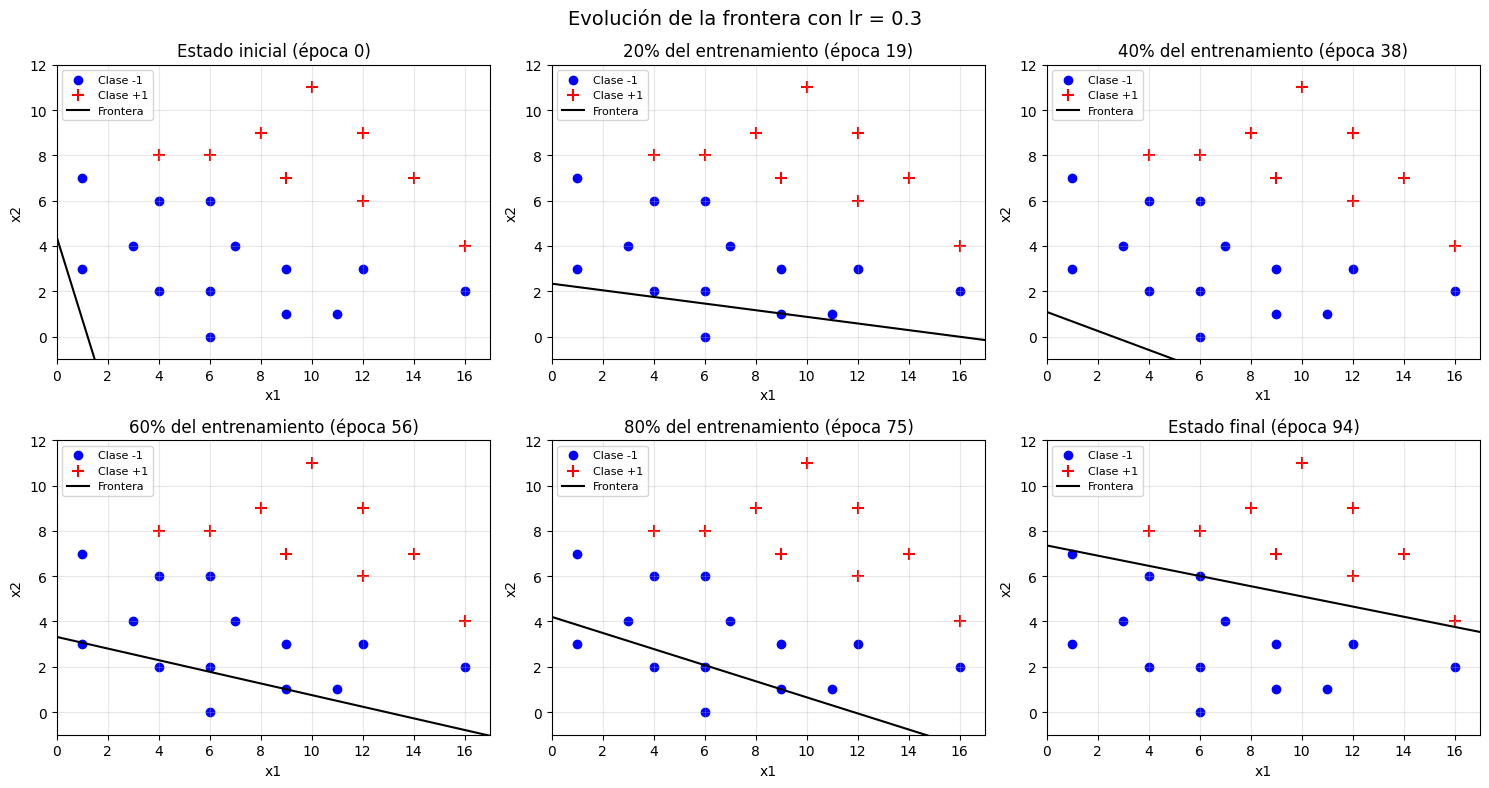

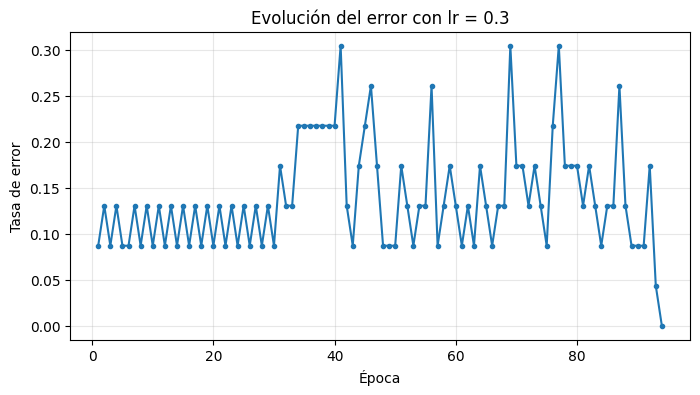


==================  lr = 0.5  ==================


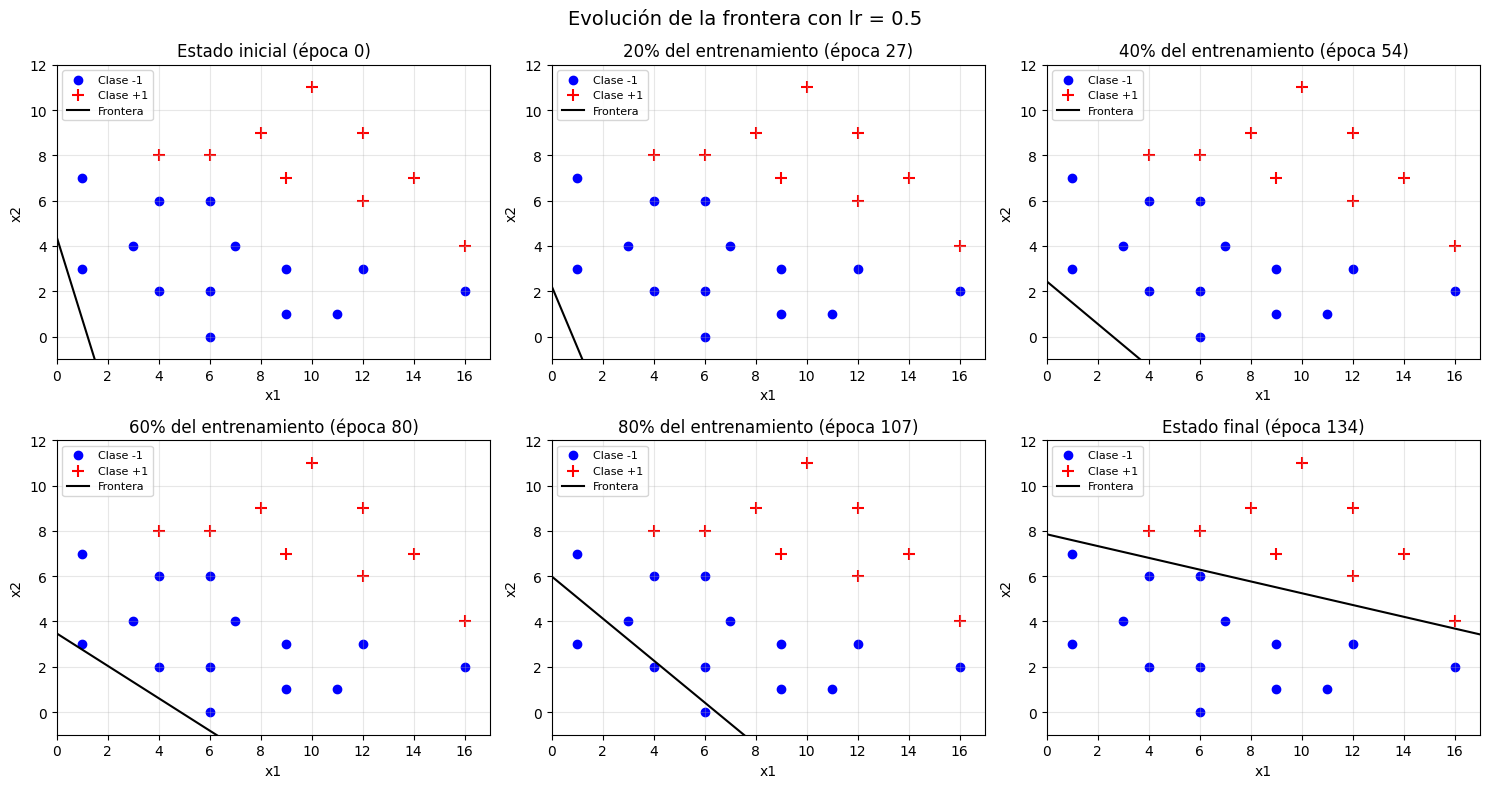

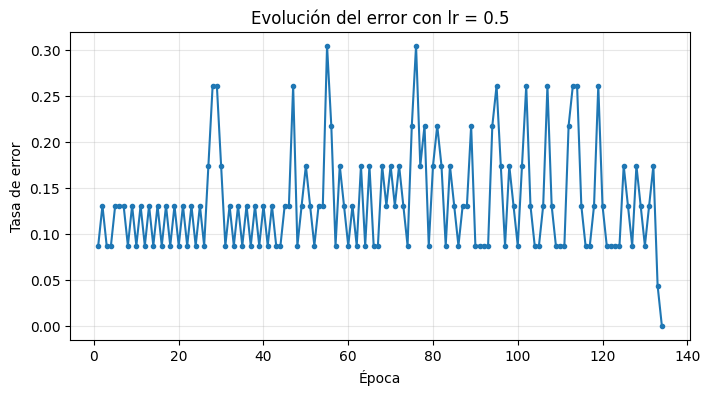


==================  lr = 0.8  ==================


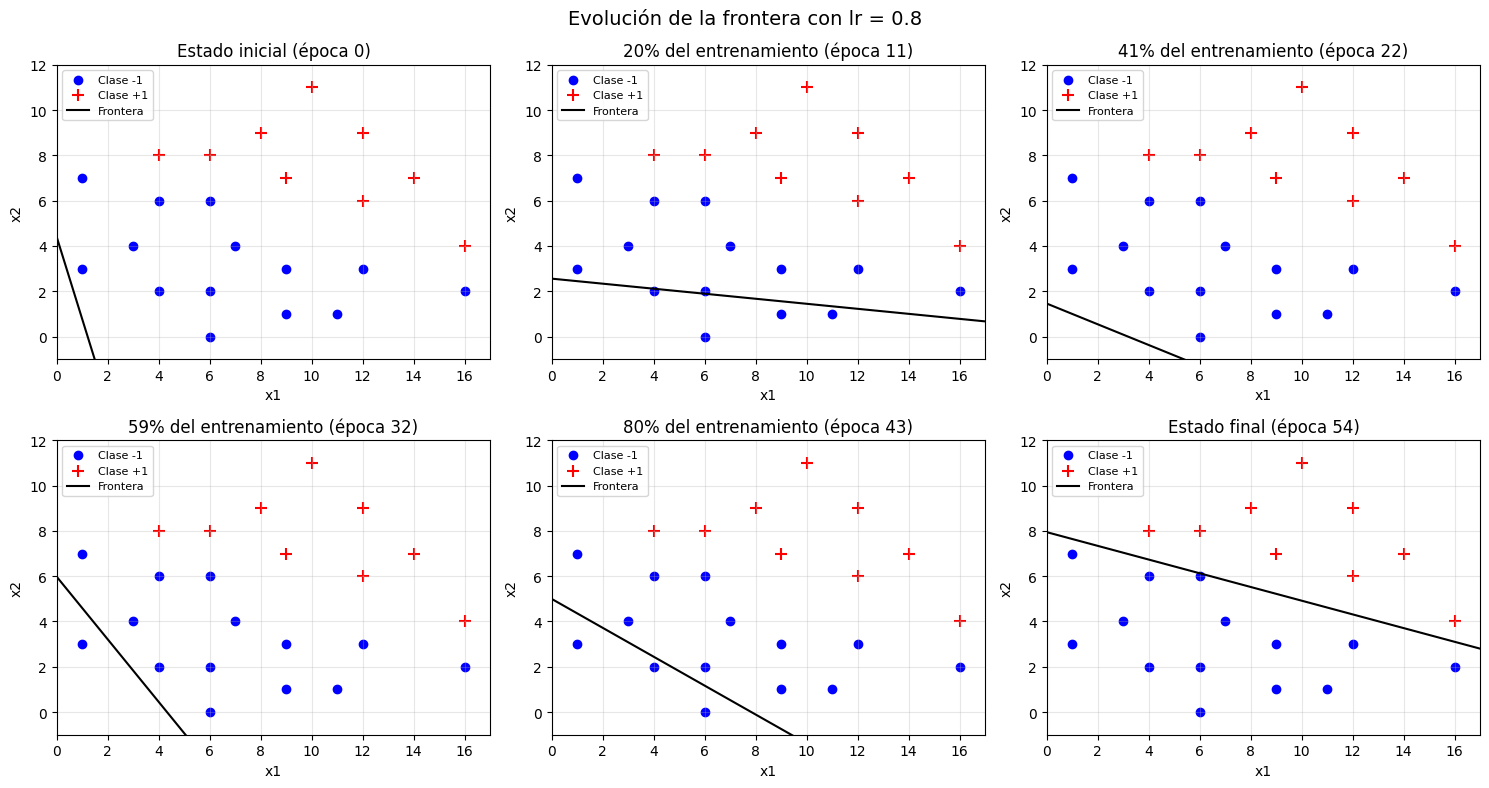

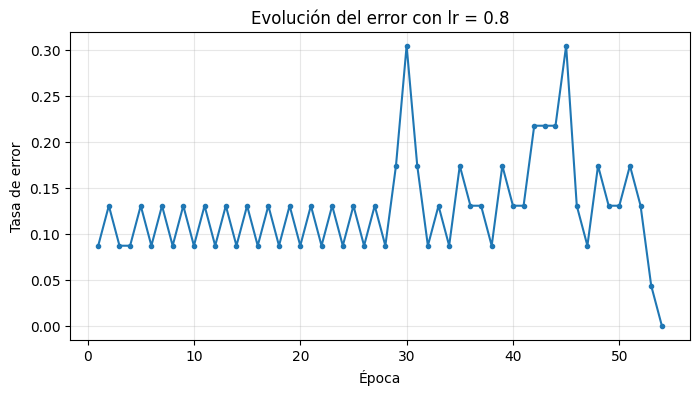

In [23]:
for lr in tasas:
    r = resultados[lr]
    print(f"\n==================  lr = {lr}  ==================")
    plot_evolution(r["W"], X, y, f"Evolución de la frontera con lr = {lr}")
    plot_error(r["E"], f"Evolución del error con lr = {lr}")

Para responder P20 con más rigor se repite el experimento con **30 semillas distintas** (30 conjuntos de pesos iniciales) y se cuenta qué tasa converge primero en cada caso:

In [24]:
from collections import Counter

epocas_por_lr = {lr: [] for lr in tasas}
for semilla in range(30):
    np.random.seed(semilla)
    w0 = initialize_weights()
    for lr in tasas:
        epocas_por_lr[lr].append(perceptron_learning(X, y, w0.copy(), lr, 1000)[1])

for lr in tasas:
    e = np.array(epocas_por_lr[lr])
    print(f"lr = {lr}: media = {e.mean():.1f} épocas | mediana = {np.median(e):.0f} | mín = {e.min()} | máx = {e.max()}")

matriz = np.array([epocas_por_lr[lr] for lr in tasas])         # shape (3, 30)
ganadoras = [tasas[i] for i in matriz.argmin(axis=0)]          # lr con menos épocas en cada semilla
print("\nVeces que cada lr fue la más rápida (de 30):", dict(Counter(ganadoras)))

lr = 0.3: media = 144.6 épocas | mediana = 130 | mín = 42 | máx = 351
lr = 0.5: media = 129.2 épocas | mediana = 119 | mín = 42 | máx = 355
lr = 0.8: media = 136.7 épocas | mediana = 115 | mín = 29 | máx = 372

Veces que cada lr fue la más rápida (de 30): {0.5: 11, 0.8: 11, 0.3: 8}


*P20. ¿Qué tasa de aprendizaje permitió alcanzar la convergencia con menos épocas? ¿Eso significa necesariamente que es la mejor tasa de aprendizaje?*

**Respuesta:** Con los pesos iniciales compartidos, **lr = 0.8** convergió con menos épocas (54), frente a 94 con lr = 0.3 y 134 con lr = 0.5. **Pero eso no significa que sea la mejor.** El experimento con 30 semillas muestra que ninguna tasa gana de forma sistemática: lr = 0.3 fue la más rápida 8 veces, lr = 0.5 11 veces y lr = 0.8 11 veces, y las medias de épocas son similares (145, 129 y 137). Además, el orden de esta ejecución (la lr = 0.5 de la Fase 5 resultó ser la más lenta) depende del vector inicial elegido. La razón de fondo es que, con pesos iniciales pequeños, η actúa sobre todo como un **factor de escala** de la solución, y lo que determina el número de épocas es la secuencia concreta de errores. Por otro lado, "menos épocas" no es el único criterio: también cuentan la estabilidad y el tamaño de los pesos finales (aquí la mayor magnitud de bias la tuvo lr = 0.5). Por eso con una sola ejecución no se puede concluir cuál es mejor.

# 3. Actividad 9.c: Tabla comparativa
---

In [25]:
print(f"{'lr':<6}{'Épocas':<10}{'Actualizaciones':<18}{'Error final':<14}{'Pesos finales'}")
for lr in tasas:
    r = resultados[lr]
    print(f"{lr:<6}{r['epocas']:<10}{r['updates']:<18}{r['E'][-1]:<14}{r['w'].round(3)}")

# ── Relación entre los pesos finales: ¿definen rectas parecidas? ──
print("\nPendiente (-w1/w2) e intercepto (-w0/w2) de cada frontera final:")
for lr in tasas:
    wf = resultados[lr]["w"]
    print(f"lr = {lr}: pendiente = {-wf[1]/wf[2]:.3f} | intercepto = {-wf[0]/wf[2]:.3f}")

lr    Épocas    Actualizaciones   Error final   Pesos finales
0.3   94        300               0.0           [-31.642   0.966   4.301]
0.5   134       413               0.0           [-71.442   2.366   9.101]
0.8   54        158               0.0           [-51.642   1.966   6.501]

Pendiente (-w1/w2) e intercepto (-w0/w2) de cada frontera final:
lr = 0.3: pendiente = -0.225 | intercepto = 7.357
lr = 0.5: pendiente = -0.260 | intercepto = 7.850
lr = 0.8: pendiente = -0.302 | intercepto = 7.944


*P21. ¿Los pesos finales son iguales para todas las tasas de aprendizaje? Si son diferentes, ¿por qué pueden producir igualmente una clasificación correcta?*

**Respuesta:** **No son iguales.** Los pesos finales fueron [-31.642,   0.966,   4.301] (lr = 0.3), [-71.442,   2.366,   9.101] (lr = 0.5) y [-51.642,   1.966,   6.501] (lr = 0.8). Aun así los tres logran **error 0**, porque lo que importa para clasificar es el **signo de z**, y muchos vectores de pesos distintos definen rectas que separan los mismos puntos. Además, multiplicar todos los pesos por una constante positiva no cambia el signo de z y por tanto no cambia la recta: las rectas finales tienen pendientes -0.22, -0.26 y -0.30 e interceptos 7.4, 7.8 y 7.9: son rectas parecidas pero no idénticas. En un dataset linealmente separable existe una **región** de soluciones válidas y el perceptrón se detiene en la primera que encuentra, que depende de η y de los pesos iniciales.

**Entregable de la Fase 9:** entrenamientos con lr = 0.3, 0.5 y 0.8, tabla comparativa, gráficas de frontera y de error para cada tasa de aprendizaje y respuestas a las preguntas guía (P19 a P21).

# **📊 Resultados obtenidos**
---
1.   Se implementó manualmente el perceptrón (inicialización de pesos, función de activación bipolar, cálculo de salida y regla de actualización) con NumPy, **sin librerías de machine learning**.
2.   El modelo aprendió una frontera lineal que separó las dos clases del dataset con **0 errores**: con lr = 0.5 lo logró en 134 épocas y 413 actualizaciones.
3.   Se registró y visualizó la evolución del entrenamiento con gráficas de la frontera y curvas de error. La frontera pasó de clasificar mal 14 de 23 puntos a 0 y el error **oscila** antes de llegar a cero.
4.   Se compararon tres tasas de aprendizaje con los mismos pesos iniciales: 94 épocas (lr = 0.3), 134 (lr = 0.5) y 54 (lr = 0.8). Un experimento con 30 semillas mostró que ninguna tasa es sistemáticamente más rápida.

# **✅ Conclusiones**
---
1.   El perceptrón es una **unidad de decisión lineal**: la recta `w₀ + w₁x₁ + w₂x₂ = 0` divide el plano y el signo de z determina la clase. Los tres pesos tienen funciones distintas: w₁ y w₂ fijan la inclinación y w₀ la posición. En este dataset, el bias tuvo el mayor cambio (de ≈ -0.44 a ≈ -71.4).

2.   Los datos resultaron **linealmente separables** (el error llegó a 0 en 134 épocas con lr = 0.5), pero con poco margen: el punto más cercano a la frontera final queda a ≈ 0.28 unidades. Eso explica por qué se necesitaron cientos de actualizaciones (413) para un dataset de solo 23 puntos.

3.   El error por época **no desciende de forma monótona**: subió en 55 de las 133 transiciones. Esto se debe a que el perceptrón corrige un error individual a la vez y no minimiza una pérdida global. Por eso `max_epochs` es necesario como protección ante datos no separables.

4.   Guardar `w.copy()` en cada época es indispensable: sin copia, todas las posiciones de la lista apuntan al mismo array y la evolución de la frontera no se puede reconstruir. Es la misma lógica de vista vs. copia de NumPy vista en el taller.

5.   Con los mismos pesos iniciales, lr = 0.8 fue la más rápida (54 épocas), pero con 30 semillas distintas ninguna tasa ganó de forma sistemática; los pesos iniciales influyen tanto como η. Los pesos finales difieren entre tasas, pero definen rectas similares que clasifican igual el entrenamiento, y un error de entrenamiento 0 no garantiza un buen desempeño con datos nuevos.


6.   Se concluye que el perceptrón converge exitosamente en una frontera de decisión lineal para datos separables, y que variar la tasa de aprendizaje altera la velocidad de convergencia y los pesos finales del algoritmo sin impedir que el modelo encuentre una solución matemáticamente válida.

# **💡 Recomendaciones**
---
1.   Fijar siempre una semilla (`np.random.seed`) al inicio para que los pesos aleatorios y los resultados sean reproducibles y verificables.
2.   Guardar copias (`.copy()`) de cualquier arreglo que se modifique dentro de un ciclo si se quiere conservar su historia.
3.   Comparar tasas de aprendizaje con **los mismos pesos iniciales** y, si es posible, repetir con varias semillas antes de concluir cuál es mejor.
4.   Reservar algunas instancias con etiqueta real como conjunto de prueba para medir la generalización; el error de entrenamiento 0 no es suficiente.
5.   Antes de entregar, ejecutar todas las celdas en orden (Entorno de ejecución > Reiniciar y ejecutar todo) para confirmar que no existan errores.

<h1 style="text-align:center"><b>📚 Referencias</b></h1>
<hr>

<p style="padding-left:2em; text-indent:-2em">
Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., ... Oliphant, T. E. (2020). Array programming with NumPy. <i>Nature, 585</i>(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2
</p>

<p style="padding-left:2em; text-indent:-2em">
Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. <i>Computing in Science &amp; Engineering, 9</i>(3), 90–95. https://doi.org/10.1109/MCSE.2007.55
</p>

<p style="padding-left:2em; text-indent:-2em">
Tufiño, R. (2026). <i>Guía de práctica de laboratorio N.° 03: El perceptrón</i> [Material de clase, Inteligencia Artificial]. Universidad Salesiana del Ecuador - Sede sur.
</p>